# Regression

Companion notebook for the *Regression* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn tool that does the same job.

**Data:** the Diabetes data (442 patients, 10 measurements, a number that measures
disease progression one year later).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

RANDOM_STATE = 42
DEGREE = 3

diabetes = load_diabetes(as_frame=True)
X, y = diabetes.data.to_numpy(), diabetes.target.to_numpy()
bmi = diabetes.data["bmi"].to_numpy()

## 1. A line through the data

For one feature, least squares gives
$\theta_1 = \dfrac{\sum_i (x_i - \bar{x})(y_i - \bar{y})}{\sum_i (x_i - \bar{x})^2}$ and $\theta_0 = \bar{y} - \theta_1 \bar{x}$.

In [2]:
slope = np.sum((bmi - bmi.mean()) * (y - y.mean())) / np.sum((bmi - bmi.mean()) ** 2)
intercept = y.mean() - slope * bmi.mean()
print(f"by hand: y = {intercept:.1f} + {slope:.1f} x")

by hand: y = 152.1 + 949.4 x


same result: True True


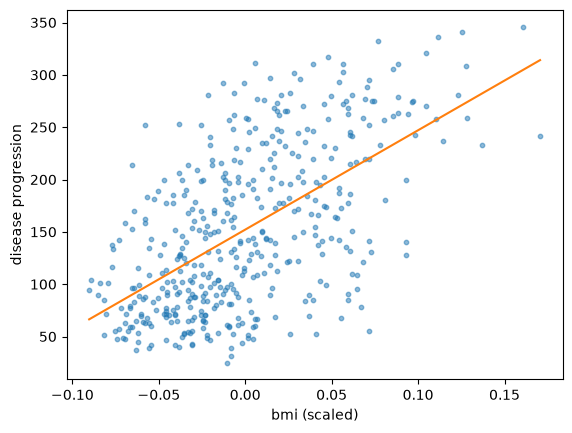

In [3]:
line = LinearRegression().fit(bmi.reshape(-1, 1), y)
print("same result:", np.isclose(slope, line.coef_[0]), np.isclose(intercept, line.intercept_))

plt.scatter(bmi, y, s=10, alpha=0.5)
plt.plot(np.sort(bmi), intercept + slope * np.sort(bmi), color="tab:orange")
plt.xlabel("bmi (scaled)")
plt.ylabel("disease progression")
plt.show()

## 2. Many features

With all features, $\hat{y} = \boldsymbol{\theta}^\top \mathbf{x}$ where $\mathbf{x}$ starts with a 1 for the intercept.
Least squares solves this directly.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

X_with_ones = np.column_stack([np.ones(len(X_train)), X_train])
theta, *_ = np.linalg.lstsq(X_with_ones, y_train, rcond=None)

In [5]:
model = LinearRegression().fit(X_train, y_train)
print("same result:", np.allclose(theta, np.r_[model.intercept_, model.coef_]))

same result: True


## 3. Scoring a regression

$\text{MAE} = \frac{1}{n}\sum|y_i - \hat{y}_i|$, $\quad\text{MSE} = \frac{1}{n}\sum(y_i - \hat{y}_i)^2$,
$\quad R^2 = 1 - \dfrac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$.

In [6]:
y_pred = np.column_stack([np.ones(len(X_test)), X_test]) @ theta
errors = y_test - y_pred
by_hand = [np.mean(np.abs(errors)), np.mean(errors**2), 1 - np.sum(errors**2) / np.sum((y_test - y_test.mean()) ** 2)]
library = [mean_absolute_error(y_test, y_pred), mean_squared_error(y_test, y_pred), r2_score(y_test, y_pred)]
print(f"MAE {by_hand[0]:.1f}, MSE {by_hand[1]:.1f}, R2 {by_hand[2]:.3f} | same result:", np.allclose(by_hand, library))

MAE 41.9, MSE 2821.8, R2 0.477 | same result: True


## 4. Curved patterns

Polynomial regression adds the powers $x, x^2, \dots, x^p$ as new features and fits a line to them.

In [7]:
coefficients = np.polyfit(bmi, y, deg=DEGREE)
curve_by_hand = np.polyval(coefficients, bmi)

In [8]:
curve_model = make_pipeline(PolynomialFeatures(DEGREE), LinearRegression()).fit(bmi.reshape(-1, 1), y)
print("same result:", np.allclose(curve_by_hand, curve_model.predict(bmi.reshape(-1, 1))))

same result: True


## Exercises

1. Fit the line of section 1 with `s5` instead of `bmi`. Which feature predicts better?
2. Compare the test $R^2$ of the one-feature line with the model of section 2.
3. Raise the degree in section 4 to 10 and compare training and test error.